<a href="https://colab.research.google.com/github/renatobdo/doutorado/blob/main/04_comparacao_a90_a91_sim_2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Título e objetivo

# Comparação entre óbitos por dengue (A90) e dengue hemorrágica (A91)

Este notebook compara os óbitos cuja causa básica foi dengue (A90) com aqueles cuja causa básica foi dengue hemorrágica (A91).

São analisados:

- distribuição dos óbitos por tipo de dengue;
- perfil demográfico;
- causas e condições associadas;
- frequência das condições em cada grupo;
- diferenças absolutas e relativas;
- condições mais características de cada grupo.

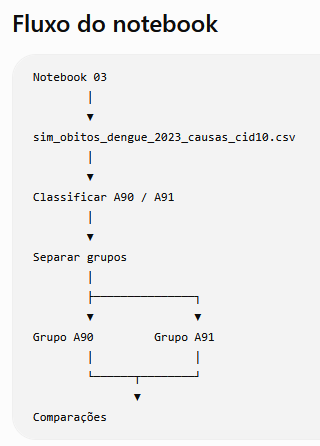

1 - Importação das bibliotecas

In [1]:
import os
import pandas as pd
import numpy as np


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2-Carregamento

3. Definição dos caminhos

In [3]:
BASE_DIR = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag"
)

CAMINHO_OBITOS = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_reduzido.csv"
)

CAMINHO_CAUSAS = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_causas_cid10.csv"
)

CAMINHO_SAIDA_RESUMO = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_resumo_a90_a91.csv"
)

CAMINHO_SAIDA_COMPARACAO = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_comparacao_causas_a90_a91.csv"
)

CAMINHO_SAIDA_DEMOGRAFICO = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_perfil_demografico_a90_a91.csv"
)

4. Verificação dos arquivos

In [4]:
arquivos_obrigatorios = [
    CAMINHO_OBITOS,
    CAMINHO_CAUSAS
]

for caminho in arquivos_obrigatorios:
    if not os.path.exists(caminho):
        raise FileNotFoundError(
            f"Arquivo não encontrado: {caminho}"
        )

print("Todos os arquivos de entrada foram encontrados.")

Todos os arquivos de entrada foram encontrados.


5. Carregamento das bases

In [5]:
df_obitos = pd.read_csv(
    CAMINHO_OBITOS,
    encoding="utf-8-sig",
    dtype="string"
)

df_causas = pd.read_csv(
    CAMINHO_CAUSAS,
    encoding="utf-8-sig",
    dtype="string"
)

print("Base de óbitos:")
print(df_obitos.shape)

print("\nBase de causas:")
print(df_causas.shape)

Base de óbitos:
(1322, 16)

Base de causas:
(6266, 9)


6. Padronização do identificador

O ideal é que o arquivo reduzido produzido pelo notebook 01 já tenha ID_REGISTRO. Caso não tenha, criamos o identificador pela ordem das linhas.

In [6]:
df_obitos = df_obitos.reset_index(drop=True).copy()

if "ID_REGISTRO" not in df_obitos.columns:
    df_obitos.insert(
        0,
        "ID_REGISTRO",
        df_obitos.index + 1
    )
else:
    df_obitos["ID_REGISTRO"] = pd.to_numeric(
        df_obitos["ID_REGISTRO"],
        errors="raise"
    ).astype("int64")

Na base de causas:

In [7]:
df_causas["ID_REGISTRO"] = pd.to_numeric(
    df_causas["ID_REGISTRO"],
    errors="raise"
).astype("int64")

Validações:

In [8]:
if not df_obitos["ID_REGISTRO"].is_unique:
    raise ValueError(
        "ID_REGISTRO não é único na base de óbitos."
    )

ids_obitos = set(df_obitos["ID_REGISTRO"])
ids_causas = set(df_causas["ID_REGISTRO"])

ids_sem_correspondencia = ids_causas - ids_obitos

print(
    "IDs da base de causas sem correspondência na base de óbitos:",
    len(ids_sem_correspondencia)
)

IDs da base de causas sem correspondência na base de óbitos: 0


O esperado é: 0

7. Normalização da causa básica

In [9]:
df_obitos["CAUSABAS_NORMALIZADA"] = (
    df_obitos["CAUSABAS"]
    .astype("string")
    .str.upper()
    .str.strip()
    .str.replace("*", "", regex=False)
    .str.replace(".", "", regex=False)
)

8. Classificação entre A90 e A91

In [10]:
condicoes = [
    df_obitos["CAUSABAS_NORMALIZADA"].str.startswith(
        "A90",
        na=False
    ),
    df_obitos["CAUSABAS_NORMALIZADA"].str.startswith(
        "A91",
        na=False
    )
]

classificacoes = [
    "Dengue (A90)",
    "Dengue hemorrágica (A91)"
]

df_obitos["TIPO_DENGUE"] = np.select(
    condicoes,
    classificacoes,
    default="Não classificado"
)

Confira:

In [11]:
df_obitos[
    [
        "ID_REGISTRO",
        "CAUSABAS",
        "CAUSABAS_NORMALIZADA",
        "TIPO_DENGUE"
    ]
].head(20)

,ID_REGISTRO,CAUSABAS,CAUSABAS_NORMALIZADA,TIPO_DENGUE
0,1,A91,A91,Dengue hemorrágica (A91)
1,2,A91,A91,Dengue hemorrágica (A91)
2,3,A91,A91,Dengue hemorrágica (A91)
3,4,A91,A91,Dengue hemorrágica (A91)
4,5,A90,A90,Dengue (A90)
5,6,A91,A91,Dengue hemorrágica (A91)
6,7,A90,A90,Dengue (A90)
7,8,A90,A90,Dengue (A90)
8,9,A91,A91,Dengue hemorrágica (A91)
9,10,A91,A91,Dengue hemorrágica (A91)


Verifique registros não classificados:

In [12]:
df_nao_classificados = df_obitos[
    df_obitos["TIPO_DENGUE"] == "Não classificado"
]

print(
    "Registros não classificados:",
    len(df_nao_classificados)
)

if len(df_nao_classificados) > 0:
    display(
        df_nao_classificados[
            [
                "ID_REGISTRO",
                "CAUSABAS",
                "CAUSABAS_NORMALIZADA"
            ]
        ].head(20)
    )

Registros não classificados: 0


9. Resumo dos óbitos por tipo

In [13]:
resumo_por_tipo = (
    df_obitos[
        df_obitos["TIPO_DENGUE"] != "Não classificado"
    ]
    .groupby("TIPO_DENGUE")
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

In [14]:
total_obitos_classificados = (
    resumo_por_tipo["total_obitos"].sum()
)

resumo_por_tipo["percentual"] = (
    resumo_por_tipo["total_obitos"]
    / total_obitos_classificados
    * 100
).round(2)

resumo_por_tipo

,TIPO_DENGUE,total_obitos,percentual
0,Dengue (A90),839,63.46
1,Dengue hemorrágica (A91),483,36.54


10. Preparação da idade

No SIM, a variável IDADE é codificada. Os primeiros dígitos indicam a unidade:

*   4xx: idade em anos;
*   3xx: idade em meses;
*   2xx: idade em dias;
*   1xx: idade em horas;
*   0xx: idade em minutos.

Para uma comparação geral por idade em anos:

In [15]:
def converter_idade_sim_para_anos(valor):
    """
    Converte a variável IDADE do SIM para idade aproximada em anos.

    Exemplos:
    471 -> 71 anos
    405 -> 5 anos
    312 -> 12 meses
    215 -> 15 dias
    """
    if pd.isna(valor):
        return np.nan

    texto = str(valor).strip()

    if not texto.isdigit():
        return np.nan

    codigo = int(texto)

    unidade = codigo // 100
    quantidade = codigo % 100

    if unidade == 4:
        return float(quantidade)

    if unidade == 3:
        return quantidade / 12

    if unidade == 2:
        return quantidade / 365.25

    if unidade == 1:
        return quantidade / (24 * 365.25)

    if unidade == 0:
        return quantidade / (60 * 24 * 365.25)

    if codigo in [999, 0]:
        return np.nan

    return np.nan

Aplicação:

In [16]:
df_obitos["IDADE_ANOS"] = (
    df_obitos["IDADE"]
    .apply(converter_idade_sim_para_anos)
)

Confira:

In [17]:
df_obitos[
    [
        "IDADE",
        "IDADE_ANOS"
    ]
].head(20)

,IDADE,IDADE_ANOS
0,465,65.0
1,483,83.0
2,455,55.0
3,500,NaN
4,477,77.0
5,433,33.0
6,421,21.0
7,480,80.0
8,445,45.0
9,486,86.0


11. Resumo da idade por grupo

In [18]:
resumo_idade = (
    df_obitos[
        df_obitos["TIPO_DENGUE"] != "Não classificado"
    ]
    .groupby("TIPO_DENGUE")
    .agg(
        total_idades_validas=("IDADE_ANOS", "count"),
        idade_media=("IDADE_ANOS", "mean"),
        idade_mediana=("IDADE_ANOS", "median"),
        idade_minima=("IDADE_ANOS", "min"),
        idade_maxima=("IDADE_ANOS", "max")
    )
    .reset_index()
)

In [19]:
colunas_idade = [
    "idade_media",
    "idade_mediana",
    "idade_minima",
    "idade_maxima"
]

resumo_idade[colunas_idade] = (
    resumo_idade[colunas_idade].round(2)
)

resumo_idade

,TIPO_DENGUE,total_idades_validas,idade_media,idade_mediana,idade_minima,idade_maxima
0,Dengue (A90),835,64.03,69.0,0.07,99.0
1,Dengue hemorrágica (A91),479,55.36,59.0,0.17,98.0


12. Faixas etárias

In [20]:
faixas = [
    -np.inf,
    0.999,
    9,
    19,
    39,
    59,
    79,
    np.inf
]

rotulos = [
    "Menor de 1 ano",
    "1 a 9 anos",
    "10 a 19 anos",
    "20 a 39 anos",
    "40 a 59 anos",
    "60 a 79 anos",
    "80 anos ou mais"
]

df_obitos["FAIXA_ETARIA"] = pd.cut(
    df_obitos["IDADE_ANOS"],
    bins=faixas,
    labels=rotulos
)

Frequência por faixa:

In [21]:
perfil_faixa_etaria = (
    df_obitos[
        df_obitos["TIPO_DENGUE"] != "Não classificado"
    ]
    .groupby(
        [
            "TIPO_DENGUE",
            "FAIXA_ETARIA"
        ],
        observed=True
    )
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

Percentual dentro de cada grupo:

In [22]:
totais_tipo_demografico = (
    df_obitos[
        df_obitos["TIPO_DENGUE"] != "Não classificado"
    ]
    .groupby("TIPO_DENGUE")
    .agg(
        total_grupo=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

In [23]:
perfil_faixa_etaria = perfil_faixa_etaria.merge(
    totais_tipo_demografico,
    on="TIPO_DENGUE",
    how="left"
)

perfil_faixa_etaria["percentual_grupo"] = (
    perfil_faixa_etaria["total_obitos"]
    / perfil_faixa_etaria["total_grupo"]
    * 100
).round(2)

perfil_faixa_etaria

,TIPO_DENGUE,FAIXA_ETARIA,total_obitos,total_grupo,percentual_grupo
0,Dengue (A90),Menor de 1 ano,10,839,1.19
1,Dengue (A90),1 a 9 anos,17,839,2.03
2,Dengue (A90),10 a 19 anos,23,839,2.74
3,Dengue (A90),20 a 39 anos,82,839,9.77
4,Dengue (A90),40 a 59 anos,156,839,18.59
5,Dengue (A90),60 a 79 anos,288,839,34.33
6,Dengue (A90),80 anos ou mais,259,839,30.87
7,Dengue hemorrágica (A91),Menor de 1 ano,7,483,1.45
8,Dengue hemorrágica (A91),1 a 9 anos,18,483,3.73
9,Dengue hemorrágica (A91),10 a 19 anos,26,483,5.38


13. Mapeamento de sexo

Verifique primeiro os valores:

In [24]:
df_obitos["SEXO"].value_counts(dropna=False)

,count
SEXO,
1,669
2,653


Crie o mapeamento:

In [25]:
MAPA_SEXO = {
    "1": "Masculino",
    "2": "Feminino",
    "0": "Ignorado",
    "9": "Ignorado"
}

df_obitos["SEXO_DESCRICAO"] = (
    df_obitos["SEXO"]
    .map(MAPA_SEXO)
    .fillna("Não informado")
)

Frequência:

In [26]:
perfil_sexo = (
    df_obitos[
        df_obitos["TIPO_DENGUE"] != "Não classificado"
    ]
    .groupby(
        [
            "TIPO_DENGUE",
            "SEXO_DESCRICAO"
        ]
    )
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

Percentual no grupo:

In [27]:
perfil_sexo = perfil_sexo.merge(
    totais_tipo_demografico,
    on="TIPO_DENGUE",
    how="left"
)

perfil_sexo["percentual_grupo"] = (
    perfil_sexo["total_obitos"]
    / perfil_sexo["total_grupo"]
    * 100
).round(2)

perfil_sexo

,TIPO_DENGUE,SEXO_DESCRICAO,total_obitos,total_grupo,percentual_grupo
0,Dengue (A90),Feminino,413,839,49.23
1,Dengue (A90),Masculino,426,839,50.77
2,Dengue hemorrágica (A91),Feminino,240,483,49.69
3,Dengue hemorrágica (A91),Masculino,243,483,50.31


14. Mapeamento de raça/cor

Verifique os códigos:

In [28]:
df_obitos["RACACOR"].value_counts(dropna=False)

,count
RACACOR,
1,788
4,390
2,102
<NA>,23
3,11
5,8


Mapeamento:

In [29]:
MAPA_RACA_COR = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indígena",
    "9": "Ignorada"
}

df_obitos["RACA_COR_DESCRICAO"] = (
    df_obitos["RACACOR"]
    .map(MAPA_RACA_COR)
    .fillna("Não informada")
)

Frequência:

In [30]:
perfil_raca_cor = (
    df_obitos[
        df_obitos["TIPO_DENGUE"] != "Não classificado"
    ]
    .groupby(
        [
            "TIPO_DENGUE",
            "RACA_COR_DESCRICAO"
        ]
    )
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

Percentual:

In [31]:
perfil_raca_cor = perfil_raca_cor.merge(
    totais_tipo_demografico,
    on="TIPO_DENGUE",
    how="left"
)

perfil_raca_cor["percentual_grupo"] = (
    perfil_raca_cor["total_obitos"]
    / perfil_raca_cor["total_grupo"]
    * 100
).round(2)

perfil_raca_cor

,TIPO_DENGUE,RACA_COR_DESCRICAO,total_obitos,total_grupo,percentual_grupo
0,Dengue (A90),Amarela,8,839,0.95
1,Dengue (A90),Branca,523,839,62.34
2,Dengue (A90),Indígena,3,839,0.36
3,Dengue (A90),Não informada,13,839,1.55
4,Dengue (A90),Parda,229,839,27.29
5,Dengue (A90),Preta,63,839,7.51
6,Dengue hemorrágica (A91),Amarela,3,483,0.62
7,Dengue hemorrágica (A91),Branca,265,483,54.87
8,Dengue hemorrágica (A91),Indígena,5,483,1.04
9,Dengue hemorrágica (A91),Não informada,10,483,2.07


15. Acrescentar o tipo de dengue à base de causas

Crie uma tabela de classificação:

In [32]:
df_classificacao = df_obitos[
    [
        "ID_REGISTRO",
        "CAUSABAS_NORMALIZADA",
        "TIPO_DENGUE"
    ]
].copy()

Faça o merge:

In [33]:
df_causas_com_tipo = df_causas.merge(
    df_classificacao,
    on="ID_REGISTRO",
    how="left",
    validate="many_to_one"
)

Validação:

In [34]:
print(
    df_causas_com_tipo[
        "TIPO_DENGUE"
    ].value_counts(dropna=False)
)

TIPO_DENGUE
Dengue (A90)                4050
Dengue hemorrágica (A91)    2216
Name: count, dtype: int64


Não deve haver muitos valores ausentes:

In [35]:
quantidade_sem_tipo = (
    df_causas_com_tipo["TIPO_DENGUE"]
    .isna()
    .sum()
)

print(
    "Linhas de causas sem classificação:",
    quantidade_sem_tipo
)

Linhas de causas sem classificação: 0


16. Seleção das causas associadas

Excluímos:

o campo CAUSABAS;
as próprias menções de dengue A90 e A91;
registros não classificados.

In [36]:
df_associadas_por_tipo = df_causas_com_tipo[
    (df_causas_com_tipo["CAMPO_CAUSA"] != "CAUSABAS")
    &
    (~df_causas_com_tipo["CODIGO_CATEGORIA"].isin(["A90", "A91"]))
    &
    (df_causas_com_tipo["TIPO_DENGUE"] != "Não classificado")
].copy()

17. Remoção de duplicidades por óbito

O mesmo CID pode aparecer mais de uma vez no mesmo óbito. Para calcular em quantos óbitos ele foi mencionado, conte apenas uma ocorrência por óbito:

In [37]:
df_associadas_unicas_por_tipo = (
    df_associadas_por_tipo
    .drop_duplicates(
        subset=[
            "ID_REGISTRO",
            "TIPO_DENGUE",
            "CODIGO_SIM"
        ]
    )
    .copy()
)

18. Frequências por grupo

In [38]:
frequencia_por_tipo = (
    df_associadas_unicas_por_tipo
    .groupby(
        [
            "TIPO_DENGUE",
            "CODIGO_SIM",
            "DESCRICAO_CID"
        ],
        dropna=False
    )
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

19. Total de óbitos de cada grupo

In [39]:
totais_por_tipo = (
    df_obitos[
        df_obitos["TIPO_DENGUE"] != "Não classificado"
    ]
    .groupby("TIPO_DENGUE")
    .agg(
        total_obitos_tipo=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

totais_por_tipo

,TIPO_DENGUE,total_obitos_tipo
0,Dengue (A90),839
1,Dengue hemorrágica (A91),483


20. Percentual de cada condição dentro do grupo

In [40]:
frequencia_por_tipo = frequencia_por_tipo.merge(
    totais_por_tipo,
    on="TIPO_DENGUE",
    how="left",
    validate="many_to_one"
)

frequencia_por_tipo["percentual_no_grupo"] = (
    frequencia_por_tipo["total_obitos"]
    / frequencia_por_tipo["total_obitos_tipo"]
    * 100
).round(2)

Visualização:

In [41]:
frequencia_por_tipo.sort_values(
    [
        "TIPO_DENGUE",
        "percentual_no_grupo"
    ],
    ascending=[True, False]
).head(30)

,TIPO_DENGUE,CODIGO_SIM,DESCRICAO_CID,total_obitos,total_obitos_tipo,percentual_no_grupo
6,Dengue (A90),A419,Septicemia não especificada,249,839,29.68
109,Dengue (A90),I10X,Hipertensão essencial (primária),158,839,18.83
184,Dengue (A90),J189,Pneumonia não especificada,133,839,15.85
254,Dengue (A90),N179,Insuficiência renal aguda não especificada,103,839,12.28
197,Dengue (A90),J960,Insuficiência respiratória aguda,85,839,10.13
289,Dengue (A90),R571,Choque hipovolêmico,82,839,9.77
288,Dengue (A90),R570,Choque cardiogênico,76,839,9.06
144,Dengue (A90),I509,Insuficiência cardíaca não especificada,62,839,7.39
56,Dengue (A90),E149,Diabetes mellitus não especificado - sem compl...,59,839,7.03
291,Dengue (A90),R579,Choque não especificado,53,839,6.32


21. Tabelas separadas para A90 e A91

In [42]:
frequencia_a90 = (
    frequencia_por_tipo[
        frequencia_por_tipo["TIPO_DENGUE"] == "Dengue (A90)"
    ]
    .rename(
        columns={
            "total_obitos": "obitos_a90",
            "total_obitos_tipo": "total_grupo_a90",
            "percentual_no_grupo": "percentual_a90"
        }
    )
    [
        [
            "CODIGO_SIM",
            "DESCRICAO_CID",
            "obitos_a90",
            "total_grupo_a90",
            "percentual_a90"
        ]
    ]
)

In [43]:
frequencia_a91 = (
    frequencia_por_tipo[
        frequencia_por_tipo["TIPO_DENGUE"]
        == "Dengue hemorrágica (A91)"
    ]
    .rename(
        columns={
            "total_obitos": "obitos_a91",
            "total_obitos_tipo": "total_grupo_a91",
            "percentual_no_grupo": "percentual_a91"
        }
    )
    [
        [
            "CODIGO_SIM",
            "DESCRICAO_CID",
            "obitos_a91",
            "total_grupo_a91",
            "percentual_a91"
        ]
    ]
)

22. Comparação lado a lado

Use outer, pois uma condição pode aparecer somente em um dos grupos:

In [44]:
comparacao_causas = frequencia_a90.merge(
    frequencia_a91,
    on=[
        "CODIGO_SIM",
        "DESCRICAO_CID"
    ],
    how="outer"
)

Preencha frequências ausentes:

In [45]:
colunas_numericas = [
    "obitos_a90",
    "percentual_a90",
    "obitos_a91",
    "percentual_a91"
]

comparacao_causas[colunas_numericas] = (
    comparacao_causas[colunas_numericas]
    .fillna(0)
)

Os totais dos grupos são constantes:

In [46]:
total_a90 = int(
    totais_por_tipo.loc[
        totais_por_tipo["TIPO_DENGUE"] == "Dengue (A90)",
        "total_obitos_tipo"
    ].iloc[0]
)

total_a91 = int(
    totais_por_tipo.loc[
        totais_por_tipo["TIPO_DENGUE"]
        == "Dengue hemorrágica (A91)",
        "total_obitos_tipo"
    ].iloc[0]
)

comparacao_causas["total_grupo_a90"] = total_a90
comparacao_causas["total_grupo_a91"] = total_a91

23. Diferença em pontos percentuais

In [47]:
comparacao_causas["diferenca_pp_a91_menos_a90"] = (
    comparacao_causas["percentual_a91"]
    - comparacao_causas["percentual_a90"]
).round(2)

Interpretação:

valor positivo: condição proporcionalmente mais frequente no grupo A91;
valor negativo: condição proporcionalmente mais frequente no grupo A90.

24. Razão de prevalências

In [48]:
comparacao_causas["razao_prevalencias_a91_a90"] = np.where(
    comparacao_causas["percentual_a90"] > 0,
    (
        comparacao_causas["percentual_a91"]
        / comparacao_causas["percentual_a90"]
    ),
    np.nan
)

comparacao_causas["razao_prevalencias_a91_a90"] = (
    comparacao_causas[
        "razao_prevalencias_a91_a90"
    ].round(2)
)

Quando a condição não aparece em A90, a razão fica ausente, pois ocorreria divisão por zero.

25. Indicador de presença nos grupos

In [49]:
comparacao_causas["PRESENCA_GRUPOS"] = np.select(
    [
        (
            (comparacao_causas["obitos_a90"] > 0)
            &
            (comparacao_causas["obitos_a91"] > 0)
        ),
        (
            (comparacao_causas["obitos_a90"] > 0)
            &
            (comparacao_causas["obitos_a91"] == 0)
        ),
        (
            (comparacao_causas["obitos_a90"] == 0)
            &
            (comparacao_causas["obitos_a91"] > 0)
        )
    ],
    [
        "Presente em A90 e A91",
        "Exclusiva de A90",
        "Exclusiva de A91"
    ],
    default="Sem ocorrência"
)

26. Ordenação da tabela final

In [50]:
comparacao_causas = (
    comparacao_causas[
        [
            "CODIGO_SIM",
            "DESCRICAO_CID",
            "obitos_a90",
            "total_grupo_a90",
            "percentual_a90",
            "obitos_a91",
            "total_grupo_a91",
            "percentual_a91",
            "diferenca_pp_a91_menos_a90",
            "razao_prevalencias_a91_a90",
            "PRESENCA_GRUPOS"
        ]
    ]
    .sort_values(
        "diferenca_pp_a91_menos_a90",
        ascending=False
    )
    .reset_index(drop=True)
)

Visualize:

In [51]:
comparacao_causas.head(30)

,CODIGO_SIM,DESCRICAO_CID,obitos_a90,total_grupo_a90,percentual_a90,obitos_a91,total_grupo_a91,percentual_a91,diferenca_pp_a91_menos_a90,razao_prevalencias_a91_a90,PRESENCA_GRUPOS
0,R571,Choque hipovolêmico,82.0,839,9.77,107.0,483,22.15,12.38,2.27,Presente em A90 e A91
1,D65X,Coagulação intravascular disseminada [síndrome...,8.0,839,0.95,17.0,483,3.52,2.57,3.71,Presente em A90 e A91
2,K920,Hematêmese,6.0,839,0.72,15.0,483,3.11,2.39,4.32,Presente em A90 e A91
3,K729,"Insuficiência hepática, sem outras especificações",9.0,839,1.07,16.0,483,3.31,2.24,3.09,Presente em A90 e A91
4,D689,Defeito de coagulação não especificado,6.0,839,0.72,13.0,483,2.69,1.97,3.74,Presente em A90 e A91
5,R048,Hemorragia de outras localizações das vias res...,8.0,839,0.95,12.0,483,2.48,1.53,2.61,Presente em A90 e A91
6,R58X,Hemorragia não classificada em outra parte,3.0,839,0.36,8.0,483,1.66,1.30,4.61,Presente em A90 e A91
7,K922,"Hemorragia gastrointestinal, sem outra especif...",10.0,839,1.19,11.0,483,2.28,1.09,1.92,Presente em A90 e A91
8,F102,Transtornos mentais e comportamentais devidos ...,13.0,839,1.55,12.0,483,2.48,0.93,1.60,Presente em A90 e A91
9,I619,Hemorragia intracerebral não especificada,15.0,839,1.79,13.0,483,2.69,0.90,1.50,Presente em A90 e A91


27. Principais condições mais frequentes em A91

É recomendável estabelecer um número mínimo de ocorrências para evitar destacar condições raras.

In [52]:
MINIMO_OBITOS = 5

mais_frequentes_a91 = (
    comparacao_causas[
        (
            comparacao_causas["obitos_a91"]
            >= MINIMO_OBITOS
        )
    ]
    .sort_values(
        "diferenca_pp_a91_menos_a90",
        ascending=False
    )
    .head(20)
)

mais_frequentes_a91[
    [
        "CODIGO_SIM",
        "DESCRICAO_CID",
        "obitos_a90",
        "percentual_a90",
        "obitos_a91",
        "percentual_a91",
        "diferenca_pp_a91_menos_a90",
        "razao_prevalencias_a91_a90"
    ]
]

,CODIGO_SIM,DESCRICAO_CID,obitos_a90,percentual_a90,obitos_a91,percentual_a91,diferenca_pp_a91_menos_a90,razao_prevalencias_a91_a90
0,R571,Choque hipovolêmico,82.0,9.77,107.0,22.15,12.38,2.27
1,D65X,Coagulação intravascular disseminada [síndrome...,8.0,0.95,17.0,3.52,2.57,3.71
2,K920,Hematêmese,6.0,0.72,15.0,3.11,2.39,4.32
3,K729,"Insuficiência hepática, sem outras especificações",9.0,1.07,16.0,3.31,2.24,3.09
4,D689,Defeito de coagulação não especificado,6.0,0.72,13.0,2.69,1.97,3.74
5,R048,Hemorragia de outras localizações das vias res...,8.0,0.95,12.0,2.48,1.53,2.61
6,R58X,Hemorragia não classificada em outra parte,3.0,0.36,8.0,1.66,1.30,4.61
7,K922,"Hemorragia gastrointestinal, sem outra especif...",10.0,1.19,11.0,2.28,1.09,1.92
8,F102,Transtornos mentais e comportamentais devidos ...,13.0,1.55,12.0,2.48,0.93,1.60
9,I619,Hemorragia intracerebral não especificada,15.0,1.79,13.0,2.69,0.90,1.50


28. Principais condições mais frequentes em A90

In [53]:
mais_frequentes_a90 = (
    comparacao_causas[
        (
            comparacao_causas["obitos_a90"]
            >= MINIMO_OBITOS
        )
    ]
    .sort_values(
        "diferenca_pp_a91_menos_a90",
        ascending=True
    )
    .head(20)
)

mais_frequentes_a90[
    [
        "CODIGO_SIM",
        "DESCRICAO_CID",
        "obitos_a90",
        "percentual_a90",
        "obitos_a91",
        "percentual_a91",
        "diferenca_pp_a91_menos_a90",
        "razao_prevalencias_a91_a90"
    ]
]

,CODIGO_SIM,DESCRICAO_CID,obitos_a90,percentual_a90,obitos_a91,percentual_a91,diferenca_pp_a91_menos_a90,razao_prevalencias_a91_a90
419,A419,Septicemia não especificada,249.0,29.68,81.0,16.77,-12.91,0.57
418,J189,Pneumonia não especificada,133.0,15.85,19.0,3.93,-11.92,0.25
417,J969,Insuficiência respiratória não especificada,50.0,5.96,10.0,2.07,-3.89,0.35
416,J81X,"Edema pulmonar, não especificado de outra forma",36.0,4.29,10.0,2.07,-2.22,0.48
415,I219,Infarto agudo do miocárdio não especificado,33.0,3.93,9.0,1.86,-2.07,0.47
414,I509,Insuficiência cardíaca não especificada,62.0,7.39,26.0,5.38,-2.01,0.73
413,N179,Insuficiência renal aguda não especificada,103.0,12.28,51.0,10.56,-1.72,0.86
412,G309,Doença de Alzheimer não especificada,22.0,2.62,5.0,1.04,-1.58,0.40
411,R54X,Senilidade,26.0,3.10,8.0,1.66,-1.44,0.54
410,J159,Pneumonia bacteriana não especificada,31.0,3.69,11.0,2.28,-1.41,0.62


29. Condições exclusivas de A90

In [54]:
exclusivas_a90 = (
    comparacao_causas[
        comparacao_causas["PRESENCA_GRUPOS"]
        == "Exclusiva de A90"
    ]
    .sort_values(
        "obitos_a90",
        ascending=False
    )
)

print(
    "Condições exclusivas de A90:",
    len(exclusivas_a90)
)

exclusivas_a90.head(30)

Condições exclusivas de A90: 177


,CODIGO_SIM,DESCRICAO_CID,obitos_a90,total_grupo_a90,percentual_a90,obitos_a91,total_grupo_a91,percentual_a91,diferenca_pp_a91_menos_a90,razao_prevalencias_a91_a90,PRESENCA_GRUPOS
400,B572,Doença de Chagas (crônica) com comprometimento...,6.0,839,0.72,0.0,483,0.0,-0.72,0.0,Exclusiva de A90
389,K759,"Doença hepática inflamatória, sem outra especi...",4.0,839,0.48,0.0,483,0.0,-0.48,0.0,Exclusiva de A90
392,I709,Aterosclerose generalizada e a não especificada,4.0,839,0.48,0.0,483,0.0,-0.48,0.0,Exclusiva de A90
390,I110,Doença cardíaca hipertensiva com insuficiência...,4.0,839,0.48,0.0,483,0.0,-0.48,0.0,Exclusiva de A90
382,J440,Doença pulmonar obstrutiva crônica com infecçã...,3.0,839,0.36,0.0,483,0.0,-0.36,0.0,Exclusiva de A90
377,J841,Outras doenças pulmonares intersticiais com fi...,3.0,839,0.36,0.0,483,0.0,-0.36,0.0,Exclusiva de A90
378,I609,Hemorragia subaracnóide não especificada,3.0,839,0.36,0.0,483,0.0,-0.36,0.0,Exclusiva de A90
376,I319,Doença não especificada do pericárdio,3.0,839,0.36,0.0,483,0.0,-0.36,0.0,Exclusiva de A90
380,E142,Diabetes mellitus não especificado - com compl...,3.0,839,0.36,0.0,483,0.0,-0.36,0.0,Exclusiva de A90
381,J439,Enfisema não especificado,3.0,839,0.36,0.0,483,0.0,-0.36,0.0,Exclusiva de A90


30. Condições exclusivas de A91

In [55]:
exclusivas_a91 = (
    comparacao_causas[
        comparacao_causas["PRESENCA_GRUPOS"]
        == "Exclusiva de A91"
    ]
    .sort_values(
        "obitos_a91",
        ascending=False
    )
)

print(
    "Condições exclusivas de A91:",
    len(exclusivas_a91)
)

exclusivas_a91.head(30)

Condições exclusivas de A91: 92


,CODIGO_SIM,DESCRICAO_CID,obitos_a90,total_grupo_a90,percentual_a90,obitos_a91,total_grupo_a91,percentual_a91,diferenca_pp_a91_menos_a90,razao_prevalencias_a91_a90,PRESENCA_GRUPOS
12,R090,Asfixia,0.0,839,0.0,3.0,483,0.62,0.62,NaN,Exclusiva de A91
13,I629,Hemorragia intracraniana (não-traumática) não ...,0.0,839,0.0,3.0,483,0.62,0.62,NaN,Exclusiva de A91
20,M340,Esclerose sistêmica progressiva,0.0,839,0.0,2.0,483,0.41,0.41,NaN,Exclusiva de A91
21,R042,Hemoptise,0.0,839,0.0,2.0,483,0.41,0.41,NaN,Exclusiva de A91
22,N17X,Insuficiência renal aguda,0.0,839,0.0,2.0,483,0.41,0.41,NaN,Exclusiva de A91
23,D695,Trombocitopenia secundária,0.0,839,0.0,2.0,483,0.41,0.41,NaN,Exclusiva de A91
24,R57X,Choque não classificado em outra parte,0.0,839,0.0,2.0,483,0.41,0.41,NaN,Exclusiva de A91
25,B349,Infecção viral não especificada,0.0,839,0.0,2.0,483,0.41,0.41,NaN,Exclusiva de A91
26,R98X,Morte sem assistência,0.0,839,0.0,2.0,483,0.41,0.41,NaN,Exclusiva de A91
27,D648,Outras anemias especificadas,0.0,839,0.0,2.0,483,0.41,0.41,NaN,Exclusiva de A91


Aqui é importante ter cautela: “exclusiva” significa apenas que a condição apareceu em um grupo e não no outro nesta base analisada.

31. Top 15 de cada grupo

In [56]:
top15_a90 = (
    frequencia_a90
    .sort_values(
        "percentual_a90",
        ascending=False
    )
    .head(15)
)

top15_a91 = (
    frequencia_a91
    .sort_values(
        "percentual_a91",
        ascending=False
    )
    .head(15)
)

Visualização:

In [57]:
print("Principais condições associadas a A90")
display(top15_a90)

print("\nPrincipais condições associadas a A91")
display(top15_a91)

Principais condições associadas a A90


,CODIGO_SIM,DESCRICAO_CID,obitos_a90,total_grupo_a90,percentual_a90
6,A419,Septicemia não especificada,249,839,29.68
109,I10X,Hipertensão essencial (primária),158,839,18.83
184,J189,Pneumonia não especificada,133,839,15.85
254,N179,Insuficiência renal aguda não especificada,103,839,12.28
197,J960,Insuficiência respiratória aguda,85,839,10.13
289,R571,Choque hipovolêmico,82,839,9.77
288,R570,Choque cardiogênico,76,839,9.06
144,I509,Insuficiência cardíaca não especificada,62,839,7.39
56,E149,Diabetes mellitus não especificado - sem compl...,59,839,7.03
291,R579,Choque não especificado,53,839,6.32



Principais condições associadas a A91


,CODIGO_SIM,DESCRICAO_CID,obitos_a91,total_grupo_a91,percentual_a91
547,R571,Choque hipovolêmico,107,483,22.15
416,I10X,Hipertensão essencial (primária),89,483,18.43
336,A419,Septicemia não especificada,81,483,16.77
519,N179,Insuficiência renal aguda não especificada,51,483,10.56
478,J960,Insuficiência respiratória aguda,46,483,9.52
546,R570,Choque cardiogênico,40,483,8.28
548,R578,Outras formas de choque,30,483,6.21
378,E149,Diabetes mellitus não especificado - sem compl...,30,483,6.21
443,I509,Insuficiência cardíaca não especificada,26,483,5.38
549,R579,Choque não especificado,24,483,4.97


32. Tabela demográfica consolidada

Você pode reunir os perfis em um único DataFrame:

In [58]:
perfil_faixa_saida = perfil_faixa_etaria.rename(
    columns={
        "FAIXA_ETARIA": "CATEGORIA",
        "total_obitos": "TOTAL_OBITOS",
        "percentual_grupo": "PERCENTUAL"
    }
)

perfil_faixa_saida["VARIAVEL"] = "Faixa etária"

In [59]:
perfil_sexo_saida = perfil_sexo.rename(
    columns={
        "SEXO_DESCRICAO": "CATEGORIA",
        "total_obitos": "TOTAL_OBITOS",
        "percentual_grupo": "PERCENTUAL"
    }
)

perfil_sexo_saida["VARIAVEL"] = "Sexo"

In [60]:
perfil_raca_saida = perfil_raca_cor.rename(
    columns={
        "RACA_COR_DESCRICAO": "CATEGORIA",
        "total_obitos": "TOTAL_OBITOS",
        "percentual_grupo": "PERCENTUAL"
    }
)

perfil_raca_saida["VARIAVEL"] = "Raça/cor"

In [61]:
perfil_demografico = pd.concat(
    [
        perfil_faixa_saida[
            [
                "TIPO_DENGUE",
                "VARIAVEL",
                "CATEGORIA",
                "TOTAL_OBITOS",
                "PERCENTUAL"
            ]
        ],
        perfil_sexo_saida[
            [
                "TIPO_DENGUE",
                "VARIAVEL",
                "CATEGORIA",
                "TOTAL_OBITOS",
                "PERCENTUAL"
            ]
        ],
        perfil_raca_saida[
            [
                "TIPO_DENGUE",
                "VARIAVEL",
                "CATEGORIA",
                "TOTAL_OBITOS",
                "PERCENTUAL"
            ]
        ]
    ],
    ignore_index=True
)

perfil_demografico.head(30)

,TIPO_DENGUE,VARIAVEL,CATEGORIA,TOTAL_OBITOS,PERCENTUAL
0,Dengue (A90),Faixa etária,Menor de 1 ano,10,1.19
1,Dengue (A90),Faixa etária,1 a 9 anos,17,2.03
2,Dengue (A90),Faixa etária,10 a 19 anos,23,2.74
3,Dengue (A90),Faixa etária,20 a 39 anos,82,9.77
4,Dengue (A90),Faixa etária,40 a 59 anos,156,18.59
5,Dengue (A90),Faixa etária,60 a 79 anos,288,34.33
6,Dengue (A90),Faixa etária,80 anos ou mais,259,30.87
7,Dengue hemorrágica (A91),Faixa etária,Menor de 1 ano,7,1.45
8,Dengue hemorrágica (A91),Faixa etária,1 a 9 anos,18,3.73
9,Dengue hemorrágica (A91),Faixa etária,10 a 19 anos,26,5.38


33. Salvamento dos resultados

Resumo por grupo:

In [62]:
resumo_por_tipo.to_csv(
    CAMINHO_SAIDA_RESUMO,
    index=False,
    encoding="utf-8-sig"
)

print(
    f"Resumo salvo em:\n{CAMINHO_SAIDA_RESUMO}"
)

Resumo salvo em:
/content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/sim_obitos_dengue_2023_resumo_a90_a91.csv


Comparação das causas:

In [63]:
comparacao_causas.to_csv(
    CAMINHO_SAIDA_COMPARACAO,
    index=False,
    encoding="utf-8-sig"
)

print(
    f"Comparação salva em:\n{CAMINHO_SAIDA_COMPARACAO}"
)

Comparação salva em:
/content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/sim_obitos_dengue_2023_comparacao_causas_a90_a91.csv


Perfil demográfico:

In [64]:
perfil_demografico.to_csv(
    CAMINHO_SAIDA_DEMOGRAFICO,
    index=False,
    encoding="utf-8-sig"
)

print(
    f"Perfil demográfico salvo em:\n"
    f"{CAMINHO_SAIDA_DEMOGRAFICO}"
)

Perfil demográfico salvo em:
/content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/sim_obitos_dengue_2023_perfil_demografico_a90_a91.csv


34. Resumo final do notebook

In [65]:
print("=" * 70)
print("COMPARAÇÃO ENTRE ÓBITOS A90 E A91")
print("=" * 70)

print(f"Óbitos com causa básica A90: {total_a90:,}")
print(f"Óbitos com causa básica A91: {total_a91:,}")

print(
    f"CIDs associados distintos em A90: "
    f"{(comparacao_causas['obitos_a90'] > 0).sum():,}"
)

print(
    f"CIDs associados distintos em A91: "
    f"{(comparacao_causas['obitos_a91'] > 0).sum():,}"
)

print(
    f"Condições exclusivas de A90: "
    f"{len(exclusivas_a90):,}"
)

print(
    f"Condições exclusivas de A91: "
    f"{len(exclusivas_a91):,}"
)

print("\nMaiores diferenças favoráveis a A91:")

display(
    mais_frequentes_a91[
        [
            "CODIGO_SIM",
            "DESCRICAO_CID",
            "percentual_a90",
            "percentual_a91",
            "diferenca_pp_a91_menos_a90"
        ]
    ].head(5)
)

print("\nMaiores diferenças favoráveis a A90:")

display(
    mais_frequentes_a90[
        [
            "CODIGO_SIM",
            "DESCRICAO_CID",
            "percentual_a90",
            "percentual_a91",
            "diferenca_pp_a91_menos_a90"
        ]
    ].head(5)
)

COMPARAÇÃO ENTRE ÓBITOS A90 E A91
Óbitos com causa básica A90: 839
Óbitos com causa básica A91: 483
CIDs associados distintos em A90: 328
CIDs associados distintos em A91: 243
Condições exclusivas de A90: 177
Condições exclusivas de A91: 92

Maiores diferenças favoráveis a A91:


,CODIGO_SIM,DESCRICAO_CID,percentual_a90,percentual_a91,diferenca_pp_a91_menos_a90
0,R571,Choque hipovolêmico,9.77,22.15,12.38
1,D65X,Coagulação intravascular disseminada [síndrome...,0.95,3.52,2.57
2,K920,Hematêmese,0.72,3.11,2.39
3,K729,"Insuficiência hepática, sem outras especificações",1.07,3.31,2.24
4,D689,Defeito de coagulação não especificado,0.72,2.69,1.97



Maiores diferenças favoráveis a A90:


,CODIGO_SIM,DESCRICAO_CID,percentual_a90,percentual_a91,diferenca_pp_a91_menos_a90
419,A419,Septicemia não especificada,29.68,16.77,-12.91
418,J189,Pneumonia não especificada,15.85,3.93,-11.92
417,J969,Insuficiência respiratória não especificada,5.96,2.07,-3.89
416,J81X,"Edema pulmonar, não especificado de outra forma",4.29,2.07,-2.22
415,I219,Infarto agudo do miocárdio não especificado,3.93,1.86,-2.07


Interpretação das medidas

Considere este resultado hipotético:
| CID  | % A90 | % A91 | Diferença | Razão |
| ---- | ----: | ----: | --------: | ----: |
| R571 |   8,0 |  25,0 |      17,0 |  3,13 |

A interpretação seria:

Choque hipovolêmico foi mencionado em 8% dos óbitos classificados como A90 e em 25% dos óbitos classificados como A91. A frequência foi 17 pontos percentuais maior no grupo A91 e aproximadamente 3,13 vezes a observada no grupo A90.

Isso é uma comparação descritiva. A razão calculada não deve ser apresentada automaticamente como evidência de associação causal ou diferença estatisticamente significativa.